<a href="https://colab.research.google.com/github/virenmarcellya12/Analisis-Deret-Waktu/blob/main/Another_copy_of_3_model_split_tanpa_boxcox_Kel_4_DATA_EMAS_JURNAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import boxcox
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [1]:
import pandas as pd

df = pd.read_csv(
    "Data Kel 4_Gold Futures Historical Data.csv",
    sep=";"
)

df.head()

,Date,Price,Open,High,Low,Vol.,Change %
0,01/02/2020,"1,528.10","1,521.00","1,534.00","1,519.70",270.55K,0.33%
1,01/03/2020,"1,552.40","1,531.70","1,556.60","1,530.40",436.74K,1.59%
2,01/06/2020,"1,568.80","1,562.70","1,590.90","1,562.30",558.97K,1.06%
3,01/07/2020,"1,574.30","1,567.40","1,579.20","1,557.00",435.87K,0.35%
4,01/08/2020,"1,560.20","1,578.80","1,613.30","1,553.40",813.41K,-0.90%


In [2]:
# Mengambil hanya kolom Date dan Price
gold = df[['Date', 'Price']].copy()

# Mengganti nama Price menjadi Close
gold = gold.rename(
    columns={'Price': 'Close'}
)

# Melihat data hasil seleksi
gold.head()

,Date,Close
0,01/02/2020,"1,528.10"
1,01/03/2020,"1,552.40"
2,01/06/2020,"1,568.80"
3,01/07/2020,"1,574.30"
4,01/08/2020,"1,560.20"


## EKSPLORASI DATA

### cek tipe data

In [3]:
gold.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1501 entries, 0 to 1500
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Date    1501 non-null   object
 1   Close   1501 non-null   object
dtypes: object(2)
memory usage: 23.6+ KB


In [4]:
gold['Date'] = pd.to_datetime(
    gold['Date'],
    format='%m/%d/%Y'
)

In [5]:
gold['Close'] = (
    gold['Close']
    .astype(str)
    .str.replace(',', '', regex=False)
    .astype(float)
)

gold.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1501 entries, 0 to 1500
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    1501 non-null   datetime64[ns]
 1   Close   1501 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 23.6 KB


### statistika deskriptif

In [6]:
gold['Close'].describe()

,Close
count,1501.000000
mean,2442.139294
std,986.680793
min,1477.900000
25%,1799.200000
50%,1935.400000
75%,2736.500000
max,5354.800000


### cek missing value (NA)

In [7]:
gold.isnull().sum()

,0
Date,0
Close,0


### visualisasi data deret waktu

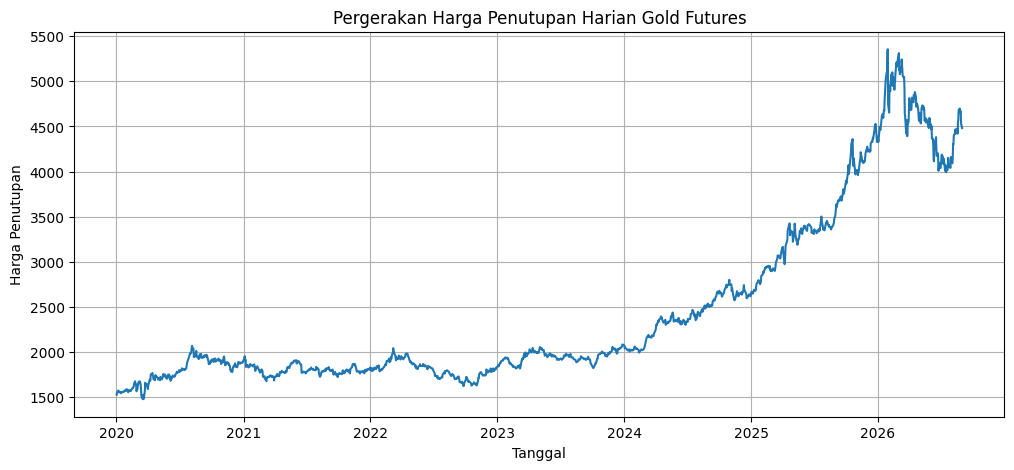

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(
    gold['Date'],
    gold['Close']
)

plt.title(
    'Pergerakan Harga Penutupan Harian Gold Futures'
)

plt.xlabel('Tanggal')
plt.ylabel('Harga Penutupan')

plt.grid(True)
plt.show()

##Split Data


Skema 1 (82% Train : 18% Test): total=1501, train=1230 (2020-01-02 s/d 2025-07-09), test=271 (2025-07-10 s/d 2026-08-31)
Skema 2 (87% Train : 13% Test): total=1501, train=1305 (2020-01-02 s/d 2025-11-18), test=196 (2025-11-19 s/d 2026-08-31)
Skema 3 (90% Train : 10% Test): total=1501, train=1350 (2020-01-02 s/d 2026-01-30), test=151 (2026-02-02 s/d 2026-08-31)


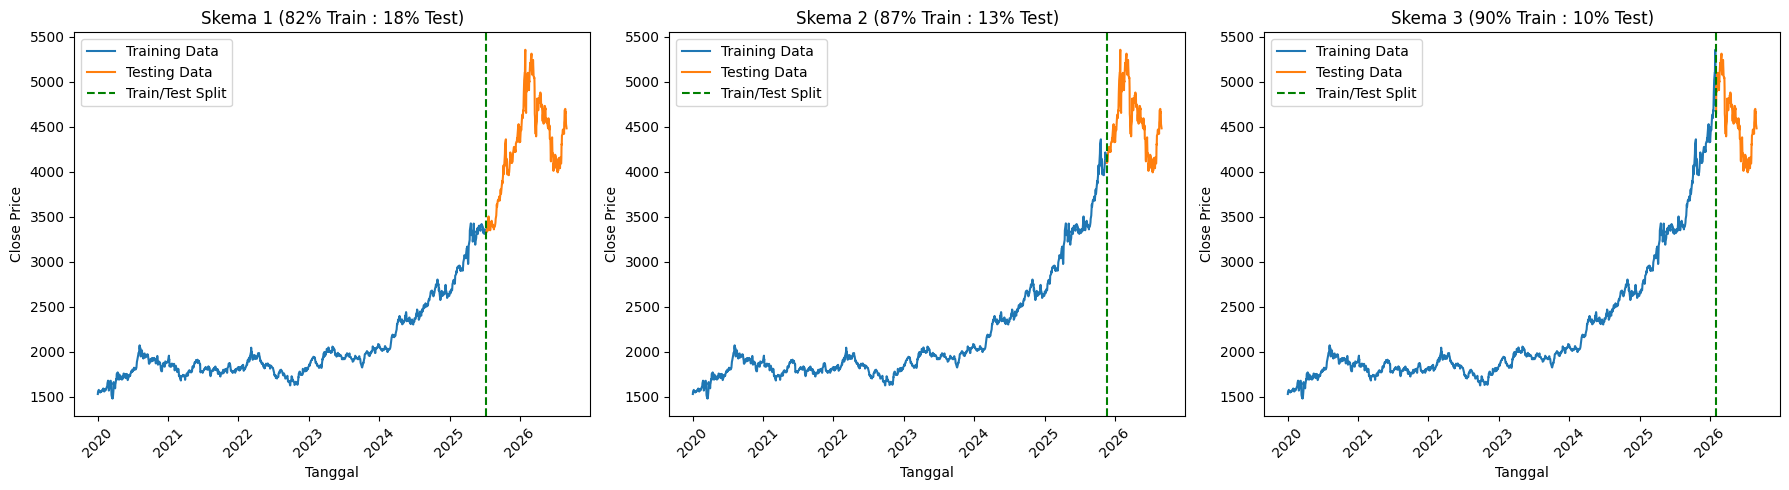

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# Pastikan 'Date' berformat datetime dan dijadikan index
df = gold.copy()
df['Date'] = pd.to_datetime(df['Date'])
df = df.set_index('Date').sort_index()

n = len(df)

# Variasikan rasio train/test pada SELURUH data hingga 2026
split_ratios = {
    "Skema 1 (82% Train : 18% Test)": 0.82,
    "Skema 2 (87% Train : 13% Test)": 0.87,
    "Skema 3 (90% Train : 10% Test)": 0.90
}

splits = {}

# Proses pembagian data berdasarkan seluruh dataset
for name, ratio in split_ratios.items():
    train_size = int(n * ratio)

    train = df.iloc[:train_size]
    test = df.iloc[train_size:]

    splits[name] = {"train": train, "test": test}

    print(f"{name}: total={n}, train={len(train)} "
          f"({train.index.min().date()} s/d {train.index.max().date()}), "
          f"test={len(test)} ({test.index.min().date()} s/d {test.index.max().date()})")

# Visualisasi grafik split data
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, sp) in zip(axes, splits.items()):
    ax.plot(sp["train"].index, sp["train"]["Close"], label="Training Data", color="tab:blue")
    ax.plot(sp["test"].index, sp["test"]["Close"], label="Testing Data", color="tab:orange")
    ax.axvline(sp["test"].index.min(), color="green", linestyle="--", label="Train/Test Split")

    ax.set_title(name)
    ax.set_xlabel("Tanggal")
    ax.set_ylabel("Close Price")
    ax.legend()
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

##Kestasioneran Data

In [25]:
import pandas as pd
from statsmodels.tsa.stattools import adfuller
from IPython.display import display


# ==========================================
# 1. FUNGSI UJI ADF
# ==========================================
def adf_report(series, label=""):
    series = pd.Series(series).dropna().astype(float)

    result = adfuller(series, autolag="AIC")

    stat = result[0]
    pval = result[1]

    status = (
        "Stasioner"
        if pval <= 0.05
        else "Tidak Stasioner"
    )

    print(
        f"{label:35s} | "
        f"ADF Stat: {stat:9.3f} | "
        f"p-value: {pval:8.4f} | "
        f"{status}"
    )

    return stat, pval, status


# ==========================================
# 2. UJI ADF SELURUH SKEMA
# ==========================================
adf_results = []

for name, sp in splits.items():

    print("\n" + "=" * 85)
    print(name)
    print("=" * 85)

    # Uji data TRAIN dan TEST
    for split_name in ["train", "test"]:

        close = (
            sp[split_name]["Close"]
            .dropna()
            .astype(float)
        )

        print(f"\n--- Data {split_name.upper()} ---")

        # Uji ADF pada level I(0)
        stat0, p0, status0 = adf_report(
            close,
            "Close I(0)"
        )

        # Uji ADF setelah differencing pertama I(1)
        close_diff = close.diff().dropna()

        stat1, p1, status1 = adf_report(
            close_diff,
            "Close I(1) - Differencing 1x"
        )

        # Indikasi orde differencing
        if p0 <= 0.05:
            d_order = 0
        elif p1 <= 0.05:
            d_order = 1
        else:
            d_order = "Periksa d > 1"

        # Simpan hasil
        adf_results.append({
            "Skema": name,
            "Split": split_name.upper(),
            "N": len(close),

            "ADF_I0": stat0,
            "p_I0": p0,
            "Status_I0": status0,

            "ADF_I1": stat1,
            "p_I1": p1,
            "Status_I1": status1,

            "d_indikatif": d_order
        })


# ==========================================
# 3. RINGKASAN DALAM SATU DATAFRAME
# ==========================================
adf_df = pd.DataFrame(adf_results)

print("\nRINGKASAN HASIL UJI ADF SELURUH SKEMA")

display(adf_df.round(5))


Skema 1 (82% Train : 18% Test)

--- Data TRAIN ---
Close I(0)                          | ADF Stat:     1.594 | p-value:   0.9978 | Tidak Stasioner
Close I(1) - Differencing 1x        | ADF Stat:   -11.965 | p-value:   0.0000 | Stasioner

--- Data TEST ---
Close I(0)                          | ADF Stat:    -2.011 | p-value:   0.2817 | Tidak Stasioner
Close I(1) - Differencing 1x        | ADF Stat:   -13.363 | p-value:   0.0000 | Stasioner

Skema 2 (87% Train : 13% Test)

--- Data TRAIN ---


/tmp/ipykernel_937/3222619981.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, autolag="AIC")
/tmp/ipykernel_937/3222619981.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, autolag="AIC")
/tmp/ipykernel_937/3222619981.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store

Close I(0)                          | ADF Stat:     3.960 | p-value:   1.0000 | Tidak Stasioner
Close I(1) - Differencing 1x        | ADF Stat:    -6.706 | p-value:   0.0000 | Stasioner

--- Data TEST ---
Close I(0)                          | ADF Stat:    -2.034 | p-value:   0.2719 | Tidak Stasioner
Close I(1) - Differencing 1x        | ADF Stat:   -11.377 | p-value:   0.0000 | Stasioner

Skema 3 (90% Train : 10% Test)

--- Data TRAIN ---
Close I(0)                          | ADF Stat:     4.268 | p-value:   1.0000 | Tidak Stasioner
Close I(1) - Differencing 1x        | ADF Stat:    -5.539 | p-value:   0.0000 | Stasioner

--- Data TEST ---
Close I(0)                          | ADF Stat:    -1.379 | p-value:   0.5921 | Tidak Stasioner
Close I(1) - Differencing 1x        | ADF Stat:   -13.161 | p-value:   0.0000 | Stasioner

RINGKASAN HASIL UJI ADF SELURUH SKEMA


/tmp/ipykernel_937/3222619981.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, autolag="AIC")
/tmp/ipykernel_937/3222619981.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, autolag="AIC")


,Skema,Split,N,ADF_I0,p_I0,Status_I0,ADF_I1,p_I1,Status_I1,d_indikatif
0,Skema 1 (82% Train : 18% Test),TRAIN,1230,1.59447,0.99784,Tidak Stasioner,-11.96500,0.0,Stasioner,1
1,Skema 1 (82% Train : 18% Test),TEST,271,-2.01107,0.28174,Tidak Stasioner,-13.36291,0.0,Stasioner,1
2,Skema 2 (87% Train : 13% Test),TRAIN,1305,3.96040,1.00000,Tidak Stasioner,-6.70645,0.0,Stasioner,1
3,Skema 2 (87% Train : 13% Test),TEST,196,-2.03397,0.27188,Tidak Stasioner,-11.37687,0.0,Stasioner,1
4,Skema 3 (90% Train : 10% Test),TRAIN,1350,4.26754,1.00000,Tidak Stasioner,-5.53874,0.0,Stasioner,1
5,Skema 3 (90% Train : 10% Test),TEST,151,-1.37943,0.59210,Tidak Stasioner,-13.16130,0.0,Stasioner,1


## Plot ACF, PACF dan EACF


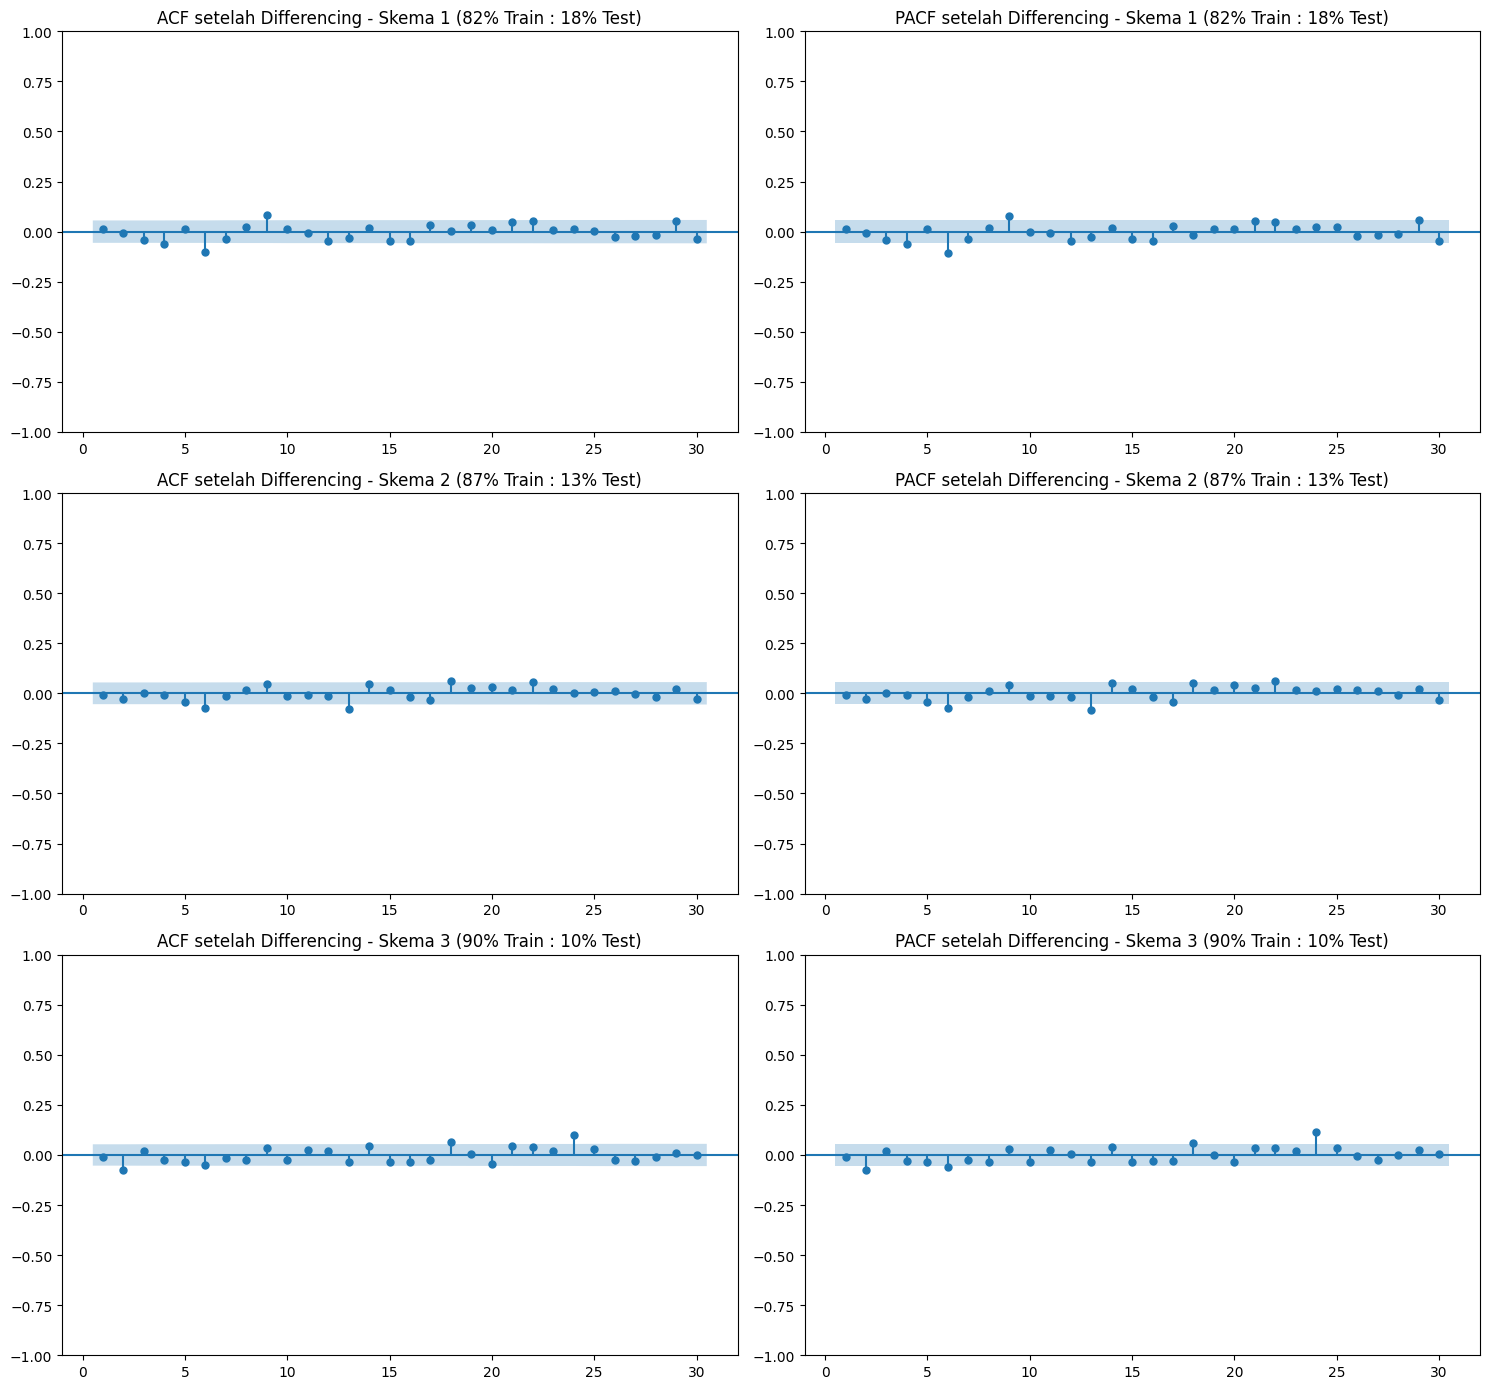

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Menyimpan data train setelah differencing
diff_train = {}

for name, sp in splits.items():

    # Ambil data train asli, tanpa Box-Cox
    train_close = sp["train"]["Close"].dropna().astype(float)

    # Differencing pertama
    train_diff = train_close.diff().dropna()

    diff_train[name] = train_diff

# Plot ACF dan PACF ketiga skema
fig, axes = plt.subplots(3, 2, figsize=(15, 14))

for i, (name, series) in enumerate(diff_train.items()):

    max_lags = min(30, len(series) // 2 - 1)

    # ACF
    plot_acf(
        series,
        lags=max_lags,
        ax=axes[i, 0],
        zero=False
    )
    axes[i, 0].set_title(f"ACF setelah Differencing - {name}")

    # PACF
    plot_pacf(
        series,
        lags=max_lags,
        ax=axes[i, 1],
        method="ywm",
        zero=False
    )
    axes[i, 1].set_title(f"PACF setelah Differencing - {name}")

plt.tight_layout()
plt.show()

In [29]:
import numpy as np
import pandas as pd

from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import acf


def eacf_python(series, ar_max=7, ma_max=7):

    y = np.asarray(series, dtype=float)
    y = y[np.isfinite(y)]

    n = len(y)
    batas = 1.96 / np.sqrt(n)

    tabel = []

    for p in range(ar_max + 1):

        if p == 0:
            residual = y - np.mean(y)

        else:
            # old_names=False dihapus agar kompatibel
            # dengan versi statsmodels di Colab
            model_ar = AutoReg(
                y,
                lags=p,
                trend="c"
            ).fit()

            residual = np.asarray(model_ar.resid)

        acf_values = acf(
            residual,
            nlags=ma_max + 1,
            fft=False
        )

        baris = []

        for q in range(ma_max + 1):

            nilai = acf_values[q + 1]

            simbol = "x" if abs(nilai) > batas else "o"
            baris.append(simbol)

        tabel.append(baris)

    hasil = pd.DataFrame(
        tabel,
        index=[f"AR {p}" for p in range(ar_max + 1)],
        columns=[f"MA {q}" for q in range(ma_max + 1)]
    )

    print(f"Batas signifikansi : ±{batas:.4f}\n")
    print(hasil.to_string())

    return hasil

In [30]:
hasil_eacf = {}

for name, series in diff_train.items():

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    hasil_eacf[name] = eacf_python(
        series,
        ar_max=7,
        ma_max=7
    )


Skema 1 (82% Train : 18% Test)
Batas signifikansi : ±0.0559

     MA 0 MA 1 MA 2 MA 3 MA 4 MA 5 MA 6 MA 7
AR 0    o    o    o    x    o    x    o    o
AR 1    o    o    o    x    o    x    o    o
AR 2    o    o    o    x    o    x    o    o
AR 3    o    o    o    x    o    x    o    o
AR 4    o    o    o    o    o    x    o    o
AR 5    o    o    o    o    o    x    o    o
AR 6    o    o    o    o    o    o    o    o
AR 7    o    o    o    o    o    o    o    o

Skema 2 (87% Train : 13% Test)
Batas signifikansi : ±0.0543

     MA 0 MA 1 MA 2 MA 3 MA 4 MA 5 MA 6 MA 7
AR 0    o    o    o    o    o    x    o    o
AR 1    o    o    o    o    o    x    o    o
AR 2    o    o    o    o    o    x    o    o
AR 3    o    o    o    o    o    x    o    o
AR 4    o    o    o    o    o    x    o    o
AR 5    o    o    o    o    o    x    o    o
AR 6    o    o    o    o    o    o    o    o
AR 7    o    o    o    o    o    o    o    o

Skema 3 (90% Train : 10% Test)
Batas signifikansi : ±0.0534

    

##Kandidat Model ARIMA


In [37]:
import numpy as np
import pandas as pd
import warnings

from statsmodels.tsa.arima.model import ARIMA
from IPython.display import display


In [38]:
candidate_orders = [
    (0, 1, 0),
    (1, 1, 0), (2, 1, 0), (3, 1, 0),
    (0, 1, 1), (0, 1, 2), (0, 1, 3),
    (1, 1, 1), (1, 1, 2), (1, 1, 3),
    (2, 1, 1), (2, 1, 2), (2, 1, 3),
    (3, 1, 1), (3, 1, 2), (3, 1, 3)
]

hasil_kandidat = []
model_fitted = {}

for nama_skema, sp in splits.items():

    train_close = sp["train"]["Close"].astype(float)

    print(f"Memodelkan: {nama_skema}")

    for order in candidate_orders:
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")

                fit = ARIMA(
                    train_close,
                    order=order
                ).fit()

            # Menghitung AICc
            k = len(fit.params)
            nobs = fit.nobs

            if nobs > k + 1:
                aicc = fit.aic + (
                    2 * k * (k + 1) / (nobs - k - 1)
                )
            else:
                aicc = np.nan

            converged = getattr(
                fit, "mle_retvals", {}
            ).get("converged", None)

            hasil_kandidat.append({
                "Skema": nama_skema,
                "Model": f"ARIMA{order}",
                "p": order[0],
                "d": order[1],
                "q": order[2],
                "AIC": fit.aic,
                "AICc": aicc,
                "BIC": fit.bic,
                "Konvergen": converged
            })

            # Simpan model yang sudah diestimasi
            model_fitted[(nama_skema, order)] = fit

        except Exception as e:
            print(f"ARIMA{order} gagal: {e}")

# Membentuk tabel seluruh kandidat
candidate_df = pd.DataFrame(hasil_kandidat)

display(
    candidate_df.sort_values(
        ["Skema", "AICc"]
    ).round(4)
)

Memodelkan: Skema 1 (82% Train : 18% Test)
Memodelkan: Skema 2 (87% Train : 13% Test)
Memodelkan: Skema 3 (90% Train : 10% Test)


,Skema,Model,p,d,q,AIC,AICc,BIC,Konvergen
15,Skema 1 (82% Train : 18% Test),"ARIMA(3, 1, 3)",3,1,3,11257.0166,11257.1083,11292.8143,False
12,Skema 1 (82% Train : 18% Test),"ARIMA(2, 1, 3)",2,1,3,11259.1926,11259.2613,11289.8764,True
14,Skema 1 (82% Train : 18% Test),"ARIMA(3, 1, 2)",3,1,2,11259.1926,11259.2613,11289.8764,True
0,Skema 1 (82% Train : 18% Test),"ARIMA(0, 1, 0)",0,1,0,11261.7115,11261.7148,11266.8255,True
11,Skema 1 (82% Train : 18% Test),"ARIMA(2, 1, 2)",2,1,2,11262.5592,11262.6083,11288.1290,True
4,Skema 1 (82% Train : 18% Test),"ARIMA(0, 1, 1)",0,1,1,11263.2641,11263.2738,11273.4920,True
1,Skema 1 (82% Train : 18% Test),"ARIMA(1, 1, 0)",1,1,0,11263.2649,11263.2747,11273.4928,True
13,Skema 1 (82% Train : 18% Test),"ARIMA(3, 1, 1)",3,1,1,11263.2538,11263.3028,11288.8236,True
10,Skema 1 (82% Train : 18% Test),"ARIMA(2, 1, 1)",2,1,1,11263.4505,11263.4832,11283.9064,True
9,Skema 1 (82% Train : 18% Test),"ARIMA(1, 1, 3)",1,1,3,11263.4871,11263.5361,11289.0569,True


In [39]:
# Hanya menggunakan model yang konvergen
candidate_valid = candidate_df[
    candidate_df["Konvergen"].eq(True)
].dropna(subset=["AICc"]).copy()

# Model dengan AICc terendah pada setiap skema
idx_best = candidate_valid.groupby("Skema")["AICc"].idxmin()

best_per_skema = (
    candidate_valid.loc[idx_best]
    .sort_values("Skema")
    .reset_index(drop=True)
)

print("MODEL TERBAIK AWAL SETIAP SKEMA")

display(
    best_per_skema[
        ["Skema", "Model", "AIC", "AICc", "BIC", "Konvergen"]
    ].round(4)
)

MODEL TERBAIK AWAL SETIAP SKEMA


,Skema,Model,AIC,AICc,BIC,Konvergen
0,Skema 1 (82% Train : 18% Test),"ARIMA(2, 1, 3)",11259.1926,11259.2613,11289.8764,True
1,Skema 2 (87% Train : 13% Test),"ARIMA(3, 1, 3)",12316.0084,12316.0948,12352.2208,True
2,Skema 3 (90% Train : 10% Test),"ARIMA(0, 1, 2)",13334.1323,13334.1501,13349.7536,True


##Diagnostik residual

In [40]:
import numpy as np
import pandas as pd
import warnings

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera
from IPython.display import display

def diagnostik_model(fit, order):

    p, d, q = order

    residual = pd.Series(
        np.asarray(fit.resid)
    ).replace([np.inf, -np.inf], np.nan).dropna()

    # Uji Ljung-Box pada lag 10 dan 20
    lb = acorr_ljungbox(
        residual,
        lags=[10, 20],
        model_df=p + q,
        return_df=True
    )

    lb10 = lb.loc[10, "lb_pvalue"]
    lb20 = lb.loc[20, "lb_pvalue"]

    # Uji Jarque-Bera
    jb_stat, jb_pvalue, _, _ = jarque_bera(residual)

    # Signifikansi parameter AR dan MA
    pvals = pd.Series(
        np.asarray(fit.pvalues),
        index=fit.param_names
    )

    mask_arma = pvals.index.str.startswith(("ar.L", "ma.L"))
    pvals_arma = pvals[mask_arma]

    if len(pvals_arma) == 0:
        status_parameter = "Tidak ada parameter AR/MA"
    else:
        tidak_signifikan = pvals_arma[
            (pvals_arma >= 0.05) | pvals_arma.isna()
        ].index.tolist()

        if len(tidak_signifikan) == 0:
            status_parameter = "Semua signifikan"
        else:
            status_parameter = (
                "Tidak signifikan: "
                + ", ".join(tidak_signifikan)
            )

    # Kecukupan residual berdasarkan Ljung-Box
    residual_white_noise = bool(
        pd.notna(lb10)
        and pd.notna(lb20)
        and lb10 > 0.05
        and lb20 > 0.05
    )

    return {
        "LB_pvalue_lag10": lb10,
        "LB_pvalue_lag20": lb20,
        "JB_pvalue": jb_pvalue,
        "Residual_white_noise": residual_white_noise,
        "Parameter_AR_MA": status_parameter
    }

In [41]:
diagnostik_awal = []

for _, row in best_per_skema.iterrows():

    nama_skema = row["Skema"]
    order = (int(row["p"]), int(row["d"]), int(row["q"]))

    fit = model_fitted[(nama_skema, order)]

    diag = diagnostik_model(fit, order)

    diagnostik_awal.append({
        "Skema": nama_skema,
        "Model": row["Model"],
        "AICc": row["AICc"],
        **diag
    })

diagnostik_awal_df = pd.DataFrame(diagnostik_awal)

print("DIAGNOSTIK MODEL TERBAIK AWAL")

display(diagnostik_awal_df.round(5))

DIAGNOSTIK MODEL TERBAIK AWAL


,Skema,Model,AICc,LB_pvalue_lag10,LB_pvalue_lag20,JB_pvalue,Residual_white_noise,Parameter_AR_MA
0,Skema 1 (82% Train : 18% Test),"ARIMA(2, 1, 3)",11259.26132,0.93216,0.99995,0.0,True,Tidak signifikan: ma.L3
1,Skema 2 (87% Train : 13% Test),"ARIMA(3, 1, 3)",12316.09480,0.91406,0.99953,0.0,True,"Tidak signifikan: ar.L1, ar.L2, ar.L3, ma.L1, ..."
2,Skema 3 (90% Train : 10% Test),"ARIMA(0, 1, 2)",13334.15012,0.95590,0.99935,0.0,True,Tidak signifikan: ma.L1


In [42]:
diagnostik_semua = []

# Memeriksa kandidat yang konvergen
for _, row in candidate_valid.sort_values(
    ["Skema", "AICc"]
).iterrows():

    nama_skema = row["Skema"]
    order = (int(row["p"]), int(row["d"]), int(row["q"]))

    fit = model_fitted[(nama_skema, order)]

    diag = diagnostik_model(fit, order)

    diagnostik_semua.append({
        **row.to_dict(),
        **diag
    })

diagnostik_semua_df = pd.DataFrame(diagnostik_semua)

# Memilih model akhir per skema
model_final = []

for nama_skema in splits.keys():

    kandidat_skema = diagnostik_semua_df[
        diagnostik_semua_df["Skema"] == nama_skema
    ].copy()

    kandidat_layak = kandidat_skema[
        kandidat_skema["Residual_white_noise"] == True
    ]

    if not kandidat_layak.empty:

        terpilih = kandidat_layak.sort_values(
            "AICc"
        ).iloc[0].copy()

        terpilih["Status_Pemilihan"] = (
            "Lolos Ljung-Box; AICc terendah di antara kandidat layak"
        )

    else:

        # Jika tidak ada kandidat yang lolos, pilih AICc terendah
        # hanya sebagai kandidat sementara
        terpilih = kandidat_skema.sort_values(
            "AICc"
        ).iloc[0].copy()

        terpilih["Status_Pemilihan"] = (
            "Belum memadai: tidak ada kandidat yang lolos "
            "Ljung-Box; perlu evaluasi ulang identifikasi model"
        )

    model_final.append(terpilih)

model_final_df = pd.DataFrame(model_final)

print("MODEL AKHIR SETIAP SKEMA")

display(
    model_final_df[
        [
            "Skema", "Model", "AICc", "BIC",
            "LB_pvalue_lag10", "LB_pvalue_lag20",
            "JB_pvalue", "Parameter_AR_MA",
            "Status_Pemilihan"
        ]
    ].round(5)
)

MODEL AKHIR SETIAP SKEMA


,Skema,Model,AICc,BIC,LB_pvalue_lag10,LB_pvalue_lag20,JB_pvalue,Parameter_AR_MA,Status_Pemilihan
0,Skema 1 (82% Train : 18% Test),"ARIMA(2, 1, 3)",11259.26132,11289.87638,0.93216,0.99995,0.0,Tidak signifikan: ma.L3,Lolos Ljung-Box; AICc terendah di antara kandi...
15,Skema 2 (87% Train : 13% Test),"ARIMA(3, 1, 3)",12316.09480,12352.22079,0.91406,0.99953,0.0,"Tidak signifikan: ar.L1, ar.L2, ar.L3, ma.L1, ...",Lolos Ljung-Box; AICc terendah di antara kandi...
31,Skema 3 (90% Train : 10% Test),"ARIMA(0, 1, 2)",13334.15012,13349.75365,0.95590,0.99935,0.0,Tidak signifikan: ma.L1,Lolos Ljung-Box; AICc terendah di antara kandi...


##Plot forecast pada data test

In [46]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

hasil_prediksi = []
hasil_akurasi = []

for _, row in model_final_df.iterrows():

    nama_skema = row["Skema"]
    order = (
        int(row["p"]),
        int(row["d"]),
        int(row["q"])
    )

    train = splits[nama_skema]["train"]
    test = splits[nama_skema]["test"]

    # Data Close pada train
    train_values = train["Close"].to_numpy(dtype=float)

    # Gunakan indeks berurutan agar forecast dapat dilakukan
    train_series = pd.Series(
        train_values,
        index=pd.RangeIndex(start=0, stop=len(train_values))
    )

    # Estimasi ulang model terpilih dengan urutan ARIMA yang sama
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        fit_forecast = ARIMA(
            train_series,
            order=order
        ).fit()

    # Ramalan sepanjang jumlah observasi test
    y_pred = np.asarray(
        fit_forecast.forecast(steps=len(test)),
        dtype=float
    )

    # Nilai aktual pada test
    y_actual = test["Close"].to_numpy(dtype=float)

    # Evaluasi akurasi
    mae = mean_absolute_error(y_actual, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_actual, y_pred)
    )

    # MAPE
    mask = y_actual != 0

    if mask.any():
        mape = np.mean(
            np.abs(
                (y_actual[mask] - y_pred[mask])
                / y_actual[mask]
            )
        ) * 100
    else:
        mape = np.nan

    hasil_akurasi.append({
        "Skema": nama_skema,
        "Model": f"ARIMA{order}",
        "N_Test": len(test),
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    })

    # Simpan prediksi beserta tanggal aktual test
    temp = pd.DataFrame({
        "Date": test.index,
        "Skema": nama_skema,
        "Model": f"ARIMA{order}",
        "Aktual": y_actual,
        "Prediksi": y_pred
    })

    hasil_prediksi.append(temp)

# Gabungkan seluruh hasil prediksi
prediksi_df = pd.concat(
    hasil_prediksi,
    ignore_index=True
)

# Tabel perbandingan akurasi
akurasi_df = pd.DataFrame(hasil_akurasi)

print("HASIL AKURASI PERAMALAN ARIMA")

display(
    akurasi_df.sort_values("RMSE").round(4)
)

HASIL AKURASI PERAMALAN ARIMA


,Skema,Model,N_Test,MAE,RMSE,MAPE (%)
2,Skema 3 (90% Train : 10% Test),"ARIMA(0, 1, 2)",151,345.9400,415.9522,7.9005
1,Skema 2 (87% Train : 13% Test),"ARIMA(3, 1, 3)",196,466.6638,571.8339,9.7508
0,Skema 1 (82% Train : 18% Test),"ARIMA(2, 1, 3)",271,1008.6669,1126.7520,22.2001


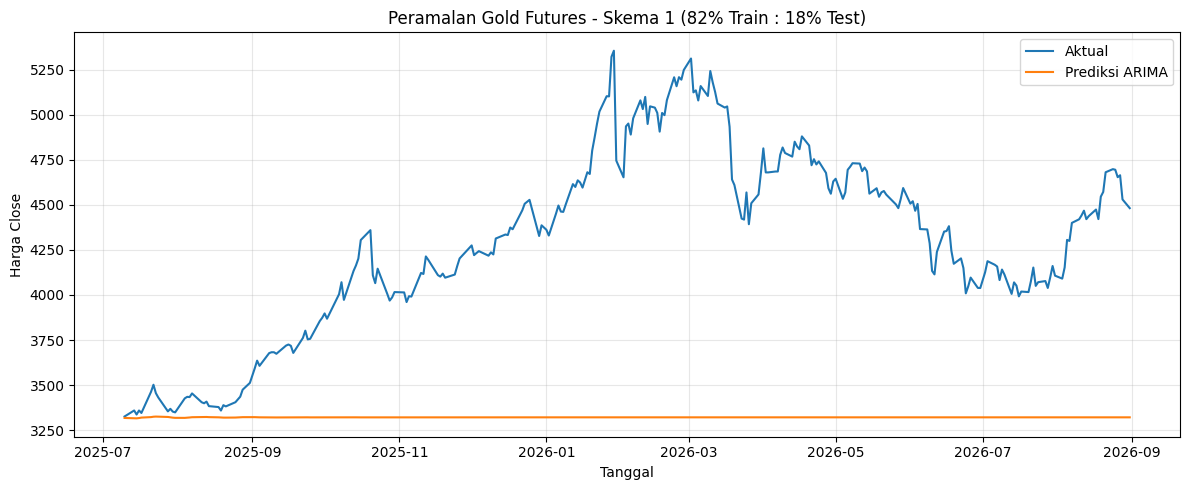

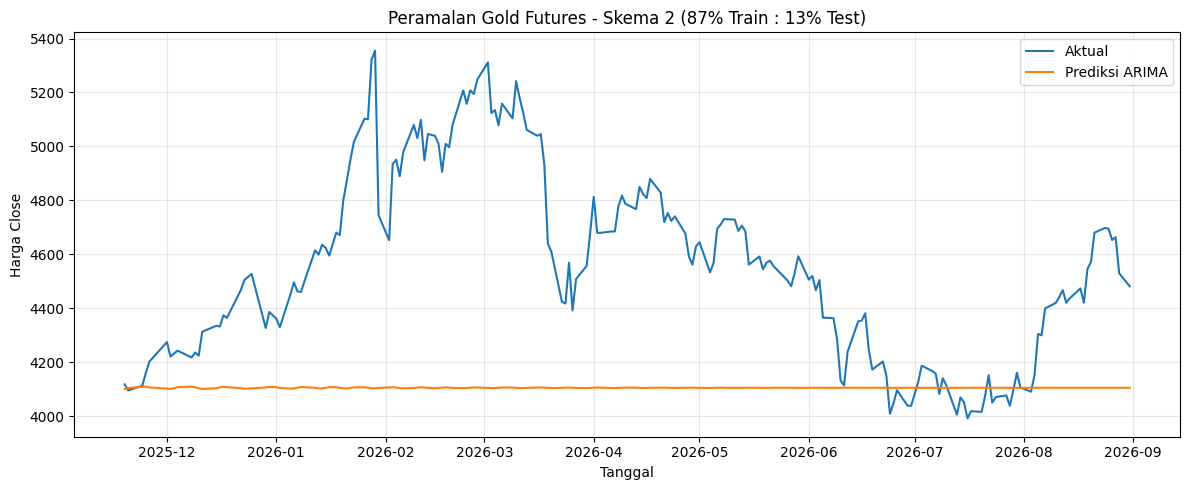

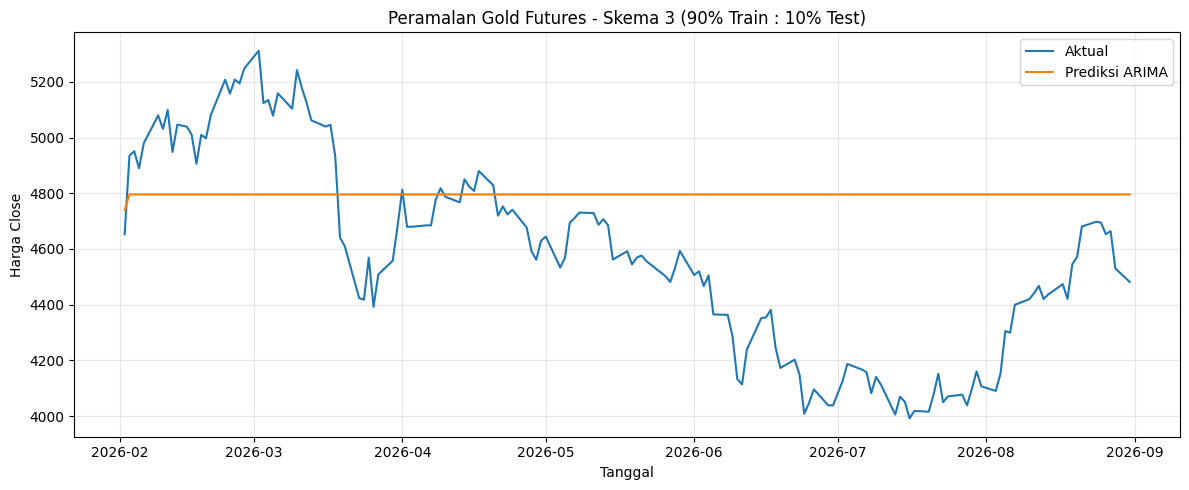

In [48]:
for nama_skema in splits.keys():

    hasil_plot = prediksi_df[
        prediksi_df["Skema"] == nama_skema
    ]

    plt.figure(figsize=(12, 5))

    plt.plot(
        hasil_plot["Date"],
        hasil_plot["Aktual"],
        label="Aktual"
    )

    plt.plot(
        hasil_plot["Date"],
        hasil_plot["Prediksi"],
        label="Prediksi ARIMA"
    )

    plt.title(f"Peramalan Gold Futures - {nama_skema}")
    plt.xlabel("Tanggal")
    plt.ylabel("Harga Close")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Memilih Skema 3
nama_skema = "Skema 3 (90% Train : 10% Test)"

model_skema3 = model_final_df[
    model_final_df["Skema"] == nama_skema
]

if model_skema3.empty:
    raise ValueError(
        "Model Skema 3 tidak ditemukan. "
        "Periksa kembali model_final_df."
    )

model_terpilih = model_skema3.iloc[0]

order = (
    int(model_terpilih["p"]),
    int(model_terpilih["d"]),
    int(model_terpilih["q"])
)

print("Skema terpilih :", nama_skema)
print("Model ARIMA    :", f"ARIMA{order}")

if "Status_Pemilihan" in model_terpilih.index:
    print("Status model   :", model_terpilih["Status_Pemilihan"])

Skema terpilih : Skema 3 (90% Train : 10% Test)
Model ARIMA    : ARIMA(0, 1, 2)
Status model   : Lolos Ljung-Box; AICc terendah di antara kandidat layak


One Step Ahead

In [50]:
import numpy as np
import pandas as pd
import warnings

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [51]:
# Mengambil data train dan test Skema 3
train = splits[nama_skema]["train"]
test = splits[nama_skema]["test"]

train_values = train["Close"].astype(float).to_numpy()
test_values = test["Close"].astype(float).to_numpy()

# Menggunakan indeks berurutan agar forecast tidak terkendala
# frekuensi tanggal perdagangan yang tidak tetap
train_series = pd.Series(
    train_values,
    index=pd.RangeIndex(start=0, stop=len(train_values))
)

# Estimasi model ARIMA pada data train
with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    fit = ARIMA(
        train_series,
        order=order
    ).fit()

# Menyimpan hasil ramalan one-step-ahead
prediksi_one_step = []

for i, (tanggal, aktual) in enumerate(test["Close"].items()):

    # 1. Ramalkan satu observasi berikutnya
    ramalan = fit.forecast(steps=1)
    prediksi = float(np.asarray(ramalan)[0])

    prediksi_one_step.append(prediksi)

    # 2. Setelah ramalan dibuat, masukkan nilai aktual
    #    untuk memperbarui informasi model pada langkah berikutnya
    indeks_baru = len(train_values) + i

    observasi_baru = pd.Series(
        [float(aktual)],
        index=pd.RangeIndex(
            start=indeks_baru,
            stop=indeks_baru + 1
        )
    )

    fit = fit.append(
        observasi_baru,
        refit=False
    )

print("Peramalan one-step-ahead selesai.")
print("Jumlah observasi test:", len(test))

Peramalan one-step-ahead selesai.
Jumlah observasi test: 151


In [52]:
hasil_one_step = pd.DataFrame({
    "Date": test.index,
    "Aktual": test_values,
    "Prediksi_One_Step_Ahead": prediksi_one_step
})

display(hasil_one_step.head(10))

,Date,Aktual,Prediksi_One_Step_Ahead
0,2026-02-02,4652.6,4739.794189
1,2026-02-03,4935.0,4708.248893
2,2026-02-04,4950.8,4944.113425
3,2026-02-05,4889.5,4929.245964
4,2026-02-06,4979.8,4888.720686
5,2026-02-09,5079.4,4983.910009
6,2026-02-10,5031.0,5071.076281
7,2026-02-11,5098.5,5021.768785
8,2026-02-12,4948.4,5102.589819
9,2026-02-13,5046.3,4940.543328


In [53]:
y_actual = hasil_one_step["Aktual"].to_numpy()
y_pred = hasil_one_step["Prediksi_One_Step_Ahead"].to_numpy()

mae = mean_absolute_error(y_actual, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_actual, y_pred)
)

# MAPE
mask = y_actual != 0

if mask.any():
    mape = np.mean(
        np.abs(
            (y_actual[mask] - y_pred[mask])
            / y_actual[mask]
        )
    ) * 100
else:
    mape = np.nan

hasil_evaluasi_one_step = pd.DataFrame({
    "Skema": [nama_skema],
    "Model": [f"ARIMA{order}"],
    "Metode": ["One-step-ahead"],
    "MAE": [mae],
    "RMSE": [rmse],
    "MAPE (%)": [mape]
})

display(hasil_evaluasi_one_step.round(4))

,Skema,Model,Metode,MAE,RMSE,MAPE (%)
0,Skema 3 (90% Train : 10% Test),"ARIMA(0, 1, 2)",One-step-ahead,61.4237,79.4965,1.342


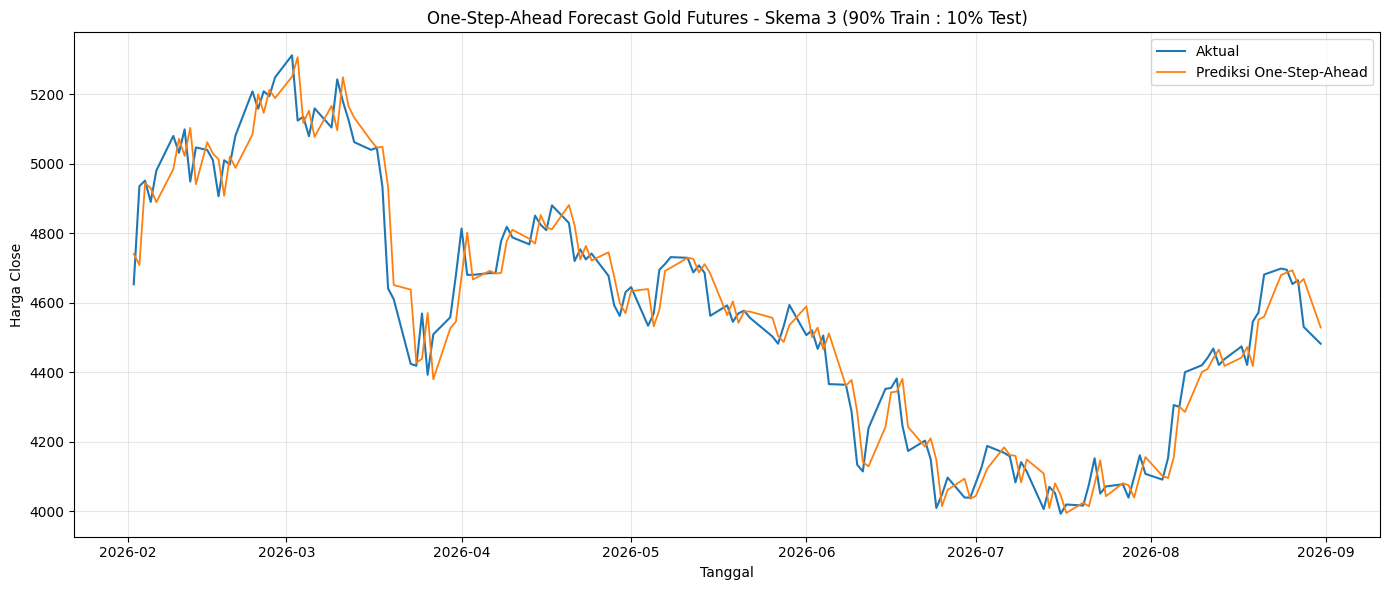

In [54]:
plt.figure(figsize=(14, 6))

plt.plot(
    hasil_one_step["Date"],
    hasil_one_step["Aktual"],
    label="Aktual",
    linewidth=1.5
)

plt.plot(
    hasil_one_step["Date"],
    hasil_one_step["Prediksi_One_Step_Ahead"],
    label="Prediksi One-Step-Ahead",
    linewidth=1.3
)

plt.title(f"One-Step-Ahead Forecast Gold Futures - {nama_skema}")
plt.xlabel("Tanggal")
plt.ylabel("Harga Close")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#LSTM

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Memilih Skema 3
nama_skema = "Skema 3 (90% Train : 10% Test)"

train = splits[nama_skema]["train"]
test = splits[nama_skema]["test"]

# Mengambil variabel Close
train_values = train["Close"].astype(float).to_numpy().reshape(-1, 1)
test_values = test["Close"].astype(float).to_numpy().reshape(-1, 1)

print("Jumlah data train:", len(train_values))
print("Jumlah data test :", len(test_values))
print("Periode train    :", train.index.min(), "s.d.", train.index.max())
print("Periode test     :", test.index.min(), "s.d.", test.index.max())

Jumlah data train: 1350
Jumlah data test : 151
Periode train    : 2020-01-02 00:00:00 s.d. 2026-01-30 00:00:00
Periode test     : 2026-02-02 00:00:00 s.d. 2026-08-31 00:00:00


In [56]:
scaler = MinMaxScaler(feature_range=(0, 1))

train_scaled = scaler.fit_transform(train_values)
test_scaled = scaler.transform(test_values)

print("Ukuran train_scaled:", train_scaled.shape)
print("Ukuran test_scaled :", test_scaled.shape)

Ukuran train_scaled: (1350, 1)
Ukuran test_scaled : (151, 1)


In [57]:
timesteps = 30

def create_sequences(data, timesteps):
    X, y = [], []

    for i in range(timesteps, len(data)):
        X.append(data[i - timesteps:i, 0])
        y.append(data[i, 0])

    X = np.array(X)
    y = np.array(y)

    return X, y


# Membentuk sequence hanya dari data train
X_train, y_train = create_sequences(
    train_scaled,
    timesteps
)

# Bentuk input LSTM: (sampel, timesteps, fitur)
X_train = X_train.reshape(
    X_train.shape[0],
    X_train.shape[1],
    1
)

print("Bentuk X_train:", X_train.shape)
print("Bentuk y_train:", y_train.shape)

Bentuk X_train: (1320, 30, 1)
Bentuk y_train: (1320,)


In [58]:
model_lstm = Sequential([
    Input(shape=(timesteps, 1)),
    LSTM(50),
    Dropout(0.2),
    Dense(1)
])

model_lstm.compile(
    optimizer="adam",
    loss="mse"
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model_lstm.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("Jumlah epoch yang dijalankan:", len(history.history["loss"]))

Epoch 1/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - loss: 0.0020 - val_loss: 0.0024
Epoch 2/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0054 - val_loss: 0.0178
Epoch 3/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0035 - val_loss: 0.0014
Epoch 4/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 8.2529e-04 - val_loss: 7.8350e-04
Epoch 5/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 4.2330e-04 - val_loss: 8.3607e-04
Epoch 6/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 5.3839e-04 - val_loss: 7.4246e-04
Epoch 7/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 4.2949e-04 - val_loss: 9.6239e-04
Epoch 8/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 4.8173e-04 - val_loss: 8.9248e-04
Epoch 9/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 6.7509e-04 - val_loss: 7.7369e-04
Epoch 10/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 3.7559e-04 - val_loss: 8.1355e-04
Epoch 11/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 3.4741e-04 - val_loss:

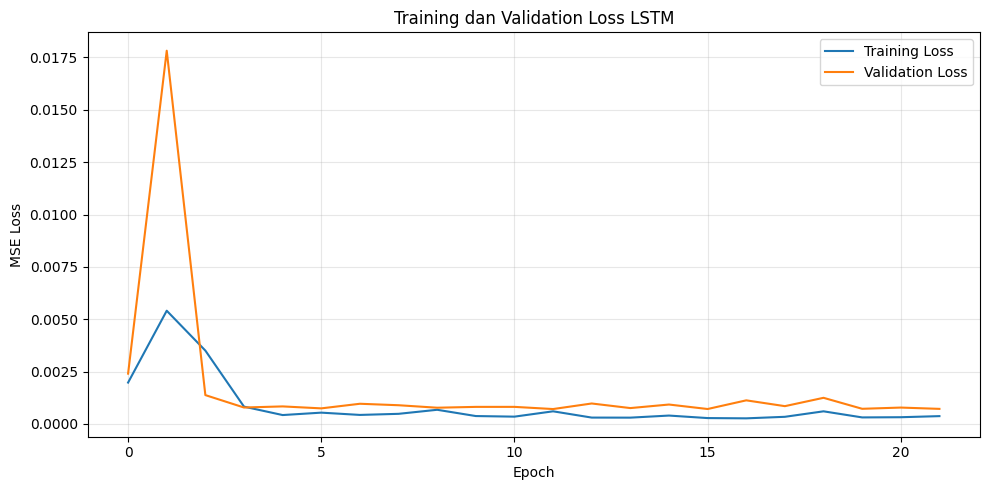

In [59]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training dan Validation Loss LSTM")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [60]:
# Gabungkan data train dan test dalam urutan waktu
all_values = np.concatenate(
    [train_values, test_values],
    axis=0
)

# Transformasi dengan scaler yang telah di-fit pada train
all_scaled = scaler.transform(all_values)

n_train = len(train_values)

# Membentuk input untuk setiap target pada periode test
X_test = []

for target_idx in range(n_train, len(all_scaled)):
    window = all_scaled[
        target_idx - timesteps:target_idx, 0
    ]
    X_test.append(window)

X_test = np.array(X_test).reshape(
    -1, timesteps, 1
)

# Prediksi pada skala normalisasi
prediksi_scaled = model_lstm.predict(
    X_test,
    verbose=0
)

# Mengembalikan prediksi ke skala harga asli
prediksi_lstm = scaler.inverse_transform(
    prediksi_scaled
).flatten()

aktual_lstm = test_values.flatten()

print("Jumlah observasi aktual :", len(aktual_lstm))
print("Jumlah hasil prediksi   :", len(prediksi_lstm))

Jumlah observasi aktual : 151
Jumlah hasil prediksi   : 151


In [61]:
hasil_lstm_one_step = pd.DataFrame({
    "Date": test.index,
    "Aktual": aktual_lstm,
    "Prediksi_LSTM": prediksi_lstm
})

display(hasil_lstm_one_step.head(10))

,Date,Aktual,Prediksi_LSTM
0,2026-02-02,4652.6,5198.375977
1,2026-02-03,4935.0,5158.072754
2,2026-02-04,4950.8,5131.057617
3,2026-02-05,4889.5,5105.808105
4,2026-02-06,4979.8,5075.502441
5,2026-02-09,5079.4,5057.913086
6,2026-02-10,5031.0,5059.069824
7,2026-02-11,5098.5,5062.427734
8,2026-02-12,4948.4,5077.278809
9,2026-02-13,5046.3,5077.126465


In [62]:
mae_lstm = mean_absolute_error(
    aktual_lstm,
    prediksi_lstm
)

rmse_lstm = np.sqrt(
    mean_squared_error(
        aktual_lstm,
        prediksi_lstm
    )
)

mask = aktual_lstm != 0

if mask.any():
    mape_lstm = np.mean(
        np.abs(
            (aktual_lstm[mask] - prediksi_lstm[mask])
            / aktual_lstm[mask]
        )
    ) * 100
else:
    mape_lstm = np.nan

hasil_evaluasi_lstm = pd.DataFrame({
    "Model": ["LSTM"],
    "Skema": [nama_skema],
    "Metode": ["One-step-ahead"],
    "MAE": [mae_lstm],
    "RMSE": [rmse_lstm],
    "MAPE (%)": [mape_lstm]
})

display(hasil_evaluasi_lstm.round(4))

,Model,Skema,Metode,MAE,RMSE,MAPE (%)
0,LSTM,Skema 3 (90% Train : 10% Test),One-step-ahead,117.935,158.1745,2.5955


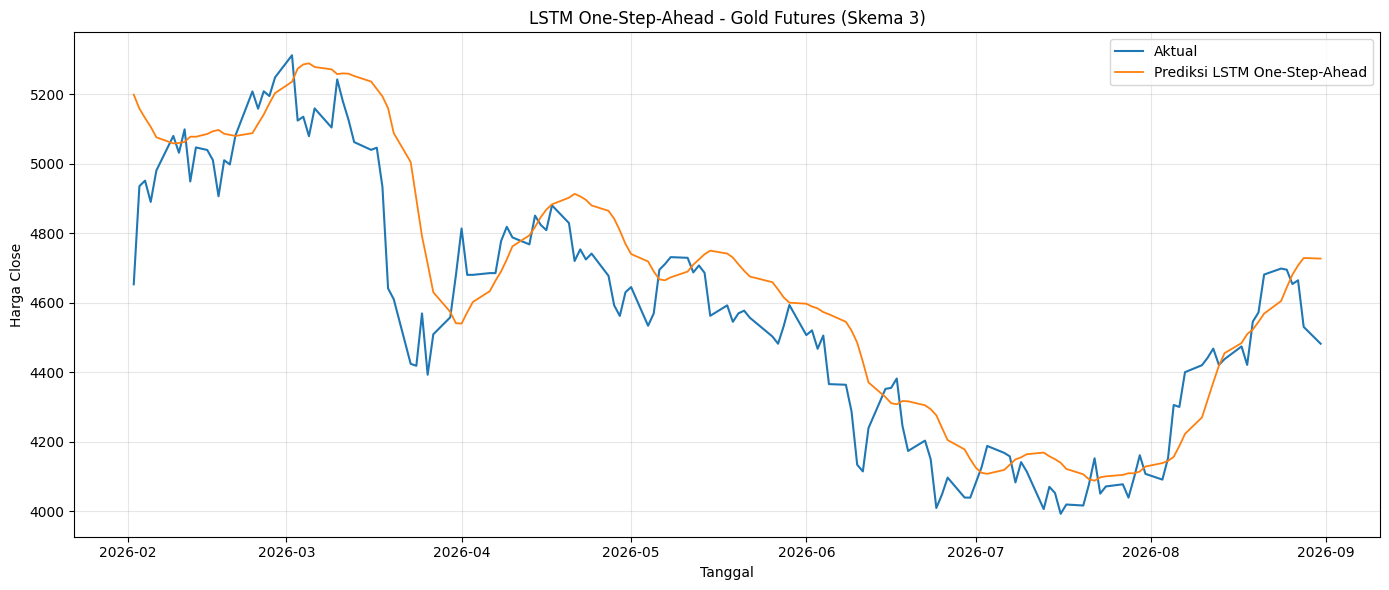

In [63]:
plt.figure(figsize=(14, 6))

plt.plot(
    hasil_lstm_one_step["Date"],
    hasil_lstm_one_step["Aktual"],
    label="Aktual",
    linewidth=1.5
)

plt.plot(
    hasil_lstm_one_step["Date"],
    hasil_lstm_one_step["Prediksi_LSTM"],
    label="Prediksi LSTM One-Step-Ahead",
    linewidth=1.3
)

plt.title("LSTM One-Step-Ahead - Gold Futures (Skema 3)")
plt.xlabel("Tanggal")
plt.ylabel("Harga Close")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##Perbandingan LSTM dan ARIMA


In [64]:
# Pastikan hasil ARIMA one-step-ahead masih tersedia
if "hasil_one_step" not in globals():
    raise NameError(
        "Variabel hasil_one_step belum tersedia. "
        "Jalankan kembali kode peramalan ARIMA one-step-ahead."
    )

# Menggabungkan hasil ARIMA dan LSTM berdasarkan tanggal
perbandingan = hasil_one_step[
    ["Date", "Aktual", "Prediksi_One_Step_Ahead"]
].merge(
    hasil_lstm_one_step[
        ["Date", "Prediksi_LSTM"]
    ],
    on="Date",
    how="inner"
)

# Menghitung metrik ARIMA dan LSTM pada tanggal yang sama
y_true = perbandingan["Aktual"].to_numpy()
pred_arima = perbandingan["Prediksi_One_Step_Ahead"].to_numpy()
pred_lstm = perbandingan["Prediksi_LSTM"].to_numpy()

hasil_perbandingan = []

for nama_model, pred in [
    ("ARIMA", pred_arima),
    ("LSTM", pred_lstm)
]:
    mae = mean_absolute_error(y_true, pred)
    rmse = np.sqrt(mean_squared_error(y_true, pred))

    mask = y_true != 0
    mape = (
        np.mean(np.abs((y_true[mask] - pred[mask]) / y_true[mask])) * 100
        if mask.any() else np.nan
    )

    hasil_perbandingan.append({
        "Model": nama_model,
        "N Test": len(y_true),
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    })

perbandingan_model_df = pd.DataFrame(hasil_perbandingan)

display(perbandingan_model_df.round(4))

,Model,N Test,MAE,RMSE,MAPE (%)
0,ARIMA,151,61.4237,79.4965,1.3420
1,LSTM,151,117.9350,158.1745,2.5955


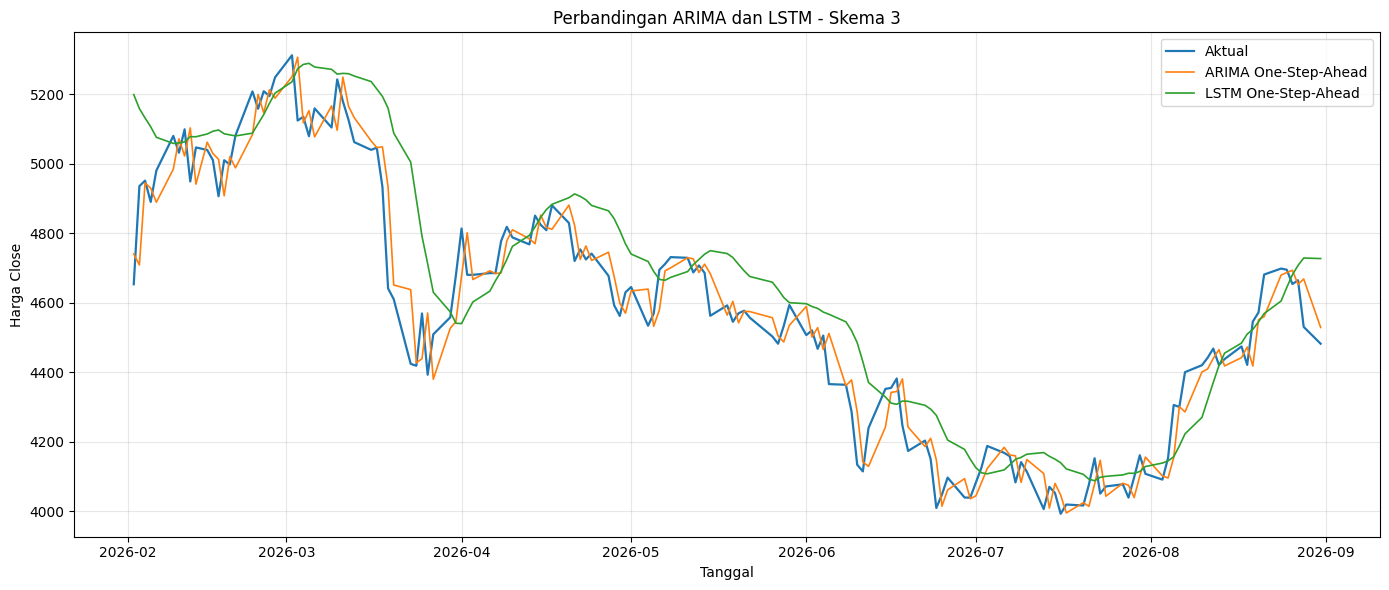

In [65]:
plt.figure(figsize=(14, 6))

plt.plot(
    perbandingan["Date"],
    perbandingan["Aktual"],
    label="Aktual",
    linewidth=1.6
)

plt.plot(
    perbandingan["Date"],
    perbandingan["Prediksi_One_Step_Ahead"],
    label="ARIMA One-Step-Ahead",
    linewidth=1.2
)

plt.plot(
    perbandingan["Date"],
    perbandingan["Prediksi_LSTM"],
    label="LSTM One-Step-Ahead",
    linewidth=1.2
)

plt.title("Perbandingan ARIMA dan LSTM - Skema 3")
plt.xlabel("Tanggal")
plt.ylabel("Harga Close")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

PEMBAGIAN DATA
Jumlah observasi : 1501
Jumlah train     : 1350
Jumlah test      : 151
Periode train    : 2020-01-02 s.d. 2026-01-30
Periode test     : 2026-02-02 s.d. 2026-08-31

PEMBENTUKAN SEQUENCE
Timesteps : 30
Bentuk X_train: (1320, 30, 1)
Bentuk y_train: (1320,)

ARSITEKTUR MODEL LSTM


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - loss: 0.0020 - val_loss: 0.0024
Epoch 2/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0054 - val_loss: 0.0178
Epoch 3/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0035 - val_loss: 0.0014
Epoch 4/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 8.2529e-04 - val_loss: 7.8350e-04
Epoch 5/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 4.2330e-04 - val_loss: 8.3607e-04
Epoch 6/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 5.3839e-04 - val_loss: 7.4246e-04
Epoch 7/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 4.2949e-04 - val_loss: 9.6239e-04
Epoch 8/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 4.8173e-04 - val_loss: 8.9248e-04
Epoch 9/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 6.7509e-04 - val_loss: 7.7369e-04
Epoch 10/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 3.7559e-04 - val_loss: 8.1355e-04
Epoch 11/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 3.4741e-04 - val_loss:

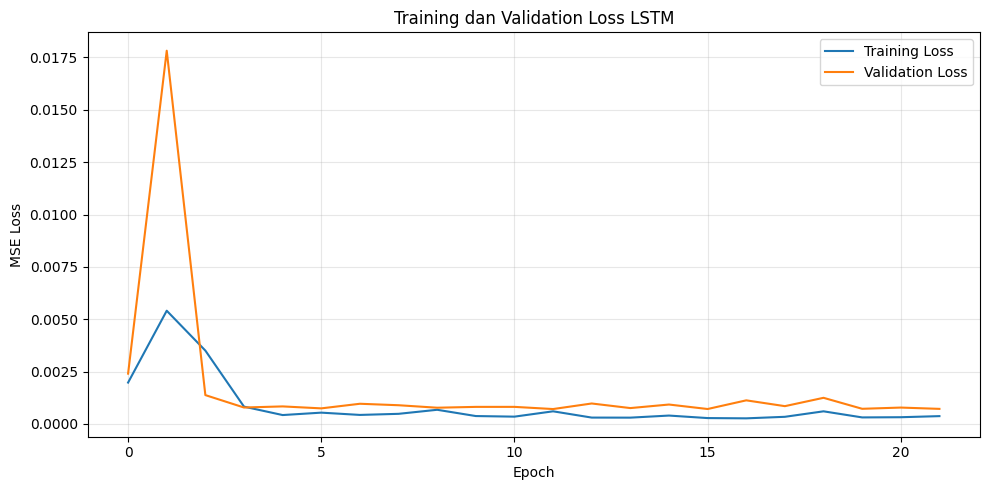


PERAMALAN ONE-STEP-AHEAD
Bentuk X_test: (151, 30, 1)

HASIL PREDIKSI LSTM


,Date,Aktual,Prediksi_LSTM,Error,Absolute_Error
0,2026-02-02,4652.6,5198.375977,-545.775977,545.775977
1,2026-02-03,4935.0,5158.072754,-223.072754,223.072754
2,2026-02-04,4950.8,5131.057617,-180.257617,180.257617
3,2026-02-05,4889.5,5105.808105,-216.308105,216.308105
4,2026-02-06,4979.8,5075.502441,-95.702441,95.702441
5,2026-02-09,5079.4,5057.913086,21.486914,21.486914
6,2026-02-10,5031.0,5059.069824,-28.069824,28.069824
7,2026-02-11,5098.5,5062.427734,36.072266,36.072266
8,2026-02-12,4948.4,5077.278809,-128.878809,128.878809
9,2026-02-13,5046.3,5077.126465,-30.826465,30.826465



EVALUASI AKURASI LSTM


,Model,Skema,Metode,N_Test,MAE,RMSE,MAPE (%)
0,LSTM,90% Train : 10% Test,One-step-ahead,151,117.935,158.1745,2.5955


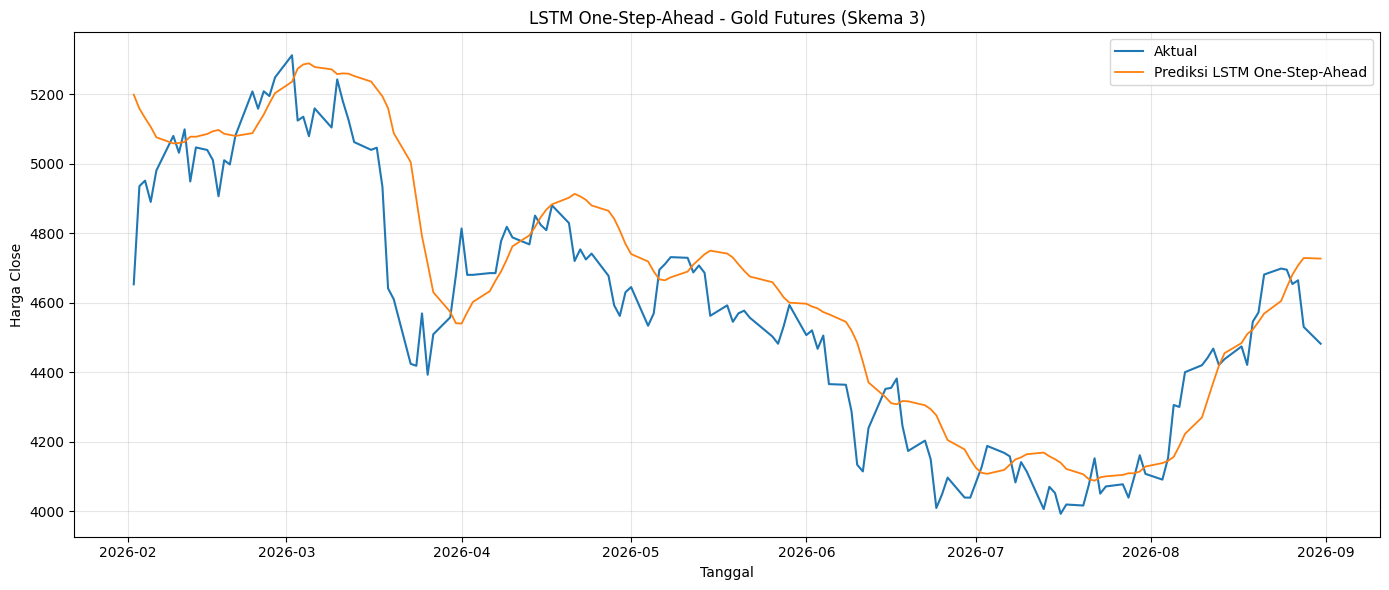

In [66]:

# ============================================================
# ANALISIS LSTM GOLD FUTURES
# SKEMA 3: 90% TRAIN : 10% TEST
# ONE-STEP-AHEAD FORECASTING
# ============================================================

import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping

from IPython.display import display

# ------------------------------------------------------------
# 1. PERSIAPAN DATA
# ------------------------------------------------------------

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

df = gold.copy()

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Close"] = pd.to_numeric(df["Close"], errors="coerce")

df = (
    df.dropna(subset=["Date", "Close"])
      .sort_values("Date")
      .drop_duplicates(subset=["Date"], keep="last")
      .set_index("Date")
)

# Pembagian kronologis: 90% train dan 10% test
n = len(df)
n_train = int(n * 0.90)

train = df.iloc[:n_train].copy()
test = df.iloc[n_train:].copy()

train_values = train["Close"].to_numpy(dtype=float).reshape(-1, 1)
test_values = test["Close"].to_numpy(dtype=float).reshape(-1, 1)

print("=" * 60)
print("PEMBAGIAN DATA")
print("=" * 60)
print("Jumlah observasi :", n)
print("Jumlah train     :", len(train))
print("Jumlah test      :", len(test))
print("Periode train    :", train.index.min().date(), "s.d.", train.index.max().date())
print("Periode test     :", test.index.min().date(), "s.d.", test.index.max().date())

# ------------------------------------------------------------
# 2. NORMALISASI DATA
# ------------------------------------------------------------

scaler = MinMaxScaler(feature_range=(0, 1))

# Scaler hanya dipelajari dari data train
train_scaled = scaler.fit_transform(train_values)

# Menggabungkan data secara kronologis, lalu mentransformasi
# menggunakan scaler yang sama
all_values = df["Close"].to_numpy(dtype=float).reshape(-1, 1)
all_scaled = scaler.transform(all_values)

# ------------------------------------------------------------
# 3. MEMBENTUK SEQUENCE
# ------------------------------------------------------------

timesteps = 30

def create_sequences(data, timesteps):
    X, y = [], []

    for i in range(timesteps, len(data)):
        X.append(data[i - timesteps:i, 0])
        y.append(data[i, 0])

    X = np.asarray(X, dtype=np.float32).reshape(
        -1, timesteps, 1
    )
    y = np.asarray(y, dtype=np.float32)

    return X, y

X_train, y_train = create_sequences(
    train_scaled,
    timesteps
)

print("\n" + "=" * 60)
print("PEMBENTUKAN SEQUENCE")
print("=" * 60)
print("Timesteps :", timesteps)
print("Bentuk X_train:", X_train.shape)
print("Bentuk y_train:", y_train.shape)

# ------------------------------------------------------------
# 4. MEMBANGUN ARSITEKTUR MODEL LSTM
# ------------------------------------------------------------

model_lstm = Sequential([
    Input(shape=(timesteps, 1)),
    LSTM(50),
    Dropout(0.2),
    Dense(1)
])

model_lstm.compile(
    optimizer="adam",
    loss="mse"
)

print("\n" + "=" * 60)
print("ARSITEKTUR MODEL LSTM")
print("=" * 60)

model_lstm.summary()

# ------------------------------------------------------------
# 5. MELATIH MODEL
# ------------------------------------------------------------

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model_lstm.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("\nPelatihan LSTM selesai.")
print("Jumlah epoch dijalankan:", len(history.history["loss"]))
print("Training loss terakhir :",
      round(history.history["loss"][-1], 6))
print("Validation loss terbaik:",
      round(min(history.history["val_loss"]), 6))

# ------------------------------------------------------------
# 6. GRAFIK LOSS PELATIHAN
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training dan Validation Loss LSTM")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. MEMBENTUK INPUT TEST ONE-STEP-AHEAD
# ------------------------------------------------------------

# Setiap target test diprediksi menggunakan 30 observasi
# tepat sebelumnya. Untuk target test berikutnya, nilai aktual
# test sebelumnya boleh digunakan sebagai input.

X_test = []

for target_idx in range(n_train, n):
    window = all_scaled[
        target_idx - timesteps:target_idx, 0
    ]
    X_test.append(window)

X_test = np.asarray(
    X_test,
    dtype=np.float32
).reshape(-1, timesteps, 1)

print("\n" + "=" * 60)
print("PERAMALAN ONE-STEP-AHEAD")
print("=" * 60)
print("Bentuk X_test:", X_test.shape)

# ------------------------------------------------------------
# 8. MELAKUKAN PREDIKSI
# ------------------------------------------------------------

prediksi_scaled = model_lstm.predict(
    X_test,
    verbose=0
)

# Mengembalikan prediksi ke skala harga Close asli
prediksi_lstm = scaler.inverse_transform(
    prediksi_scaled
).flatten()

aktual_lstm = test_values.flatten()

# ------------------------------------------------------------
# 9. TABEL HASIL PREDIKSI
# ------------------------------------------------------------

hasil_lstm_one_step = pd.DataFrame({
    "Date": test.index,
    "Aktual": aktual_lstm,
    "Prediksi_LSTM": prediksi_lstm
})

hasil_lstm_one_step["Error"] = (
    hasil_lstm_one_step["Aktual"]
    - hasil_lstm_one_step["Prediksi_LSTM"]
)

hasil_lstm_one_step["Absolute_Error"] = (
    hasil_lstm_one_step["Error"].abs()
)

print("\n" + "=" * 60)
print("HASIL PREDIKSI LSTM")
print("=" * 60)

display(hasil_lstm_one_step.head(10))

# ------------------------------------------------------------
# 10. EVALUASI AKURASI
# ------------------------------------------------------------

mae_lstm = mean_absolute_error(
    aktual_lstm,
    prediksi_lstm
)

rmse_lstm = np.sqrt(
    mean_squared_error(
        aktual_lstm,
        prediksi_lstm
    )
)

mask = aktual_lstm != 0

if mask.any():
    mape_lstm = np.mean(
        np.abs(
            (aktual_lstm[mask] - prediksi_lstm[mask])
            / aktual_lstm[mask]
        )
    ) * 100
else:
    mape_lstm = np.nan

hasil_evaluasi_lstm = pd.DataFrame({
    "Model": ["LSTM"],
    "Skema": ["90% Train : 10% Test"],
    "Metode": ["One-step-ahead"],
    "N_Test": [len(aktual_lstm)],
    "MAE": [mae_lstm],
    "RMSE": [rmse_lstm],
    "MAPE (%)": [mape_lstm]
})

print("\n" + "=" * 60)
print("EVALUASI AKURASI LSTM")
print("=" * 60)

display(hasil_evaluasi_lstm.round(4))

# ------------------------------------------------------------
# 11. GRAFIK AKTUAL VS PREDIKSI
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    hasil_lstm_one_step["Date"],
    hasil_lstm_one_step["Aktual"],
    label="Aktual",
    linewidth=1.5
)

plt.plot(
    hasil_lstm_one_step["Date"],
    hasil_lstm_one_step["Prediksi_LSTM"],
    label="Prediksi LSTM One-Step-Ahead",
    linewidth=1.3
)

plt.title("LSTM One-Step-Ahead - Gold Futures (Skema 3)")
plt.xlabel("Tanggal")
plt.ylabel("Harga Close")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
